In [ ]:
from pathlib import Path
import sys

repo_root = Path.cwd().parent
sys.path.insert(0, str(repo_root))

import numpy as np
from dist_iqp.utils import vec_to_graph, compute_average_density, compute_bipartite_percentage, compute_average_bipartivity
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from matplotlib.legend_handler import HandlerTuple
from matplotlib.ticker import MaxNLocator

### Sample Quality

In [ ]:
def aggregate_over_runs(result_dict, baseline, metric, capacity = None):
    aggregate = []
    if baseline:
        for ri in range(6):
            aggregate = aggregate + result_dict[ri][metric]
    else:
        for ri in range(6):
            aggregate = aggregate + result_dict[ri][capacity][metric]
    return aggregate

def get_means_yerrs(result_dict, metric):
    means = [np.mean(aggregate_over_runs(result_dict, False, metric, cap)) for cap in [15, 18, 21]]
    ci95_lower = [np.quantile(aggregate_over_runs(result_dict, False, metric, cap), 0.025) for cap in [15, 18, 21]]
    ci95_upper = [np.quantile(aggregate_over_runs(result_dict, False, metric, cap), 0.975) for cap in [15, 18, 21]]
    yerr = [[means[i] - ci95_lower[i] for i in range(3)], [ci95_upper[i] - means[i] for i in range(3)]]
    return means, yerr

rng = np.random.default_rng(seed=42)

def bootstrap_sample_quality(
    method_results,
    metric,
    capacity,
    n_bootstrap=5000,
    seed=42,
):
    """
    Stratified bootstrap over repetitions within six fixed circuits.

    method_results:
        {
            "Product": product_baseline_results,
            "DQC": dqc_results,
            "DQC+ProdEM": prod_dqc_results,
            "DQC+LocalCondEM": localcond_dqc_results,
        }

    Uses matching repetition indices across methods. This assumes that
    repetition r refers to the same ideal reference sample set across methods.

    Returns:
        summary: point estimates and percentile intervals for mean errors
        comparisons: paired differences relative to Product
    """
    rng = np.random.default_rng(seed)
    methods = list(method_results)
    circuits = sorted(method_results["Product"])

    errors = {}
    for method, results in method_results.items():
        errors[method] = [
            np.asarray(
                results[c][metric]
                if method == "Product"
                else results[c][capacity][metric],
                dtype=float,
            )
            for c in circuits
        ]

    for ci, circuit in enumerate(circuits):
        sizes = [len(errors[m][ci]) for m in methods]
        if len(set(sizes)) != 1 or sizes[0] == 0:
            raise ValueError(
                f"Circuit {circuit}: methods need matching, nonempty repetitions."
            )
        if any(not np.all(np.isfinite(errors[m][ci])) for m in methods):
            raise ValueError(f"Circuit {circuit}: nonfinite errors.")

    # Equal weight for each of the six circuits.
    points = {
        m: float(np.mean([values.mean() for values in errors[m]]))
        for m in methods
    }

    bootstrap_means = {
        m: np.zeros(n_bootstrap, dtype=float)
        for m in methods
    }

    for ci, circuit in enumerate(circuits):
        n_reps = len(errors["Product"][ci])
        indices = rng.integers(
            0, n_reps, size=(n_bootstrap, n_reps)
        )

        # Shared indices preserve correspondence across methods.
        for method in methods:
            bootstrap_means[method] += (
                errors[method][ci][indices].mean(axis=1) / len(circuits)
            )

    summary = {}
    for method in methods:
        summary[method] = {
            "mean": points[method],
            "ci95": np.quantile(
                bootstrap_means[method], [0.025, 0.975]
            ),
        }

    comparisons = {}
    for method in methods:
        if method == "Product":
            continue

        boot_delta = (
            bootstrap_means[method] - bootstrap_means["Product"]
        )
        comparisons[method] = {
            "delta_point": points[method] - points["Product"],
            "ci95": np.quantile(boot_delta, [0.025, 0.975]),
        }

    return summary, comparisons

In [ ]:
def compute_degree_distn_tvd(ideal_graphs, test_graphs, num_nodes):
    ideal_degrees = np.array([[d for n, d in g.degree()] for g in ideal_graphs]).flatten()
    ideal_degrees_epdf = [np.sum(ideal_degrees == i)/len(ideal_degrees) for i in range(num_nodes)]
    test_degrees = np.array([[d for n, d in g.degree()] for g in test_graphs]).flatten()
    test_degrees_epdf = [np.sum(test_degrees == i)/len(test_degrees) for i in range(num_nodes)]
    return 0.5*np.sum(np.abs(np.array(ideal_degrees_epdf) - np.array(test_degrees_epdf)))

# Product
metrics = ['density', 'BP%', 'beta', 'tvd']
product_baseline_results = {ri: {m: [] for m in metrics} for ri in range(6)}
capacity = 15
for run_idx in range(6):
    for rep in range(50):

        product_samples = np.load('./extensive_run_results/{}cap_{}run_{}rep_prod_base_samples.npy'.format(capacity, run_idx, rep))
        product_graphs = [vec_to_graph(s, 8) for s in product_samples]
        ideal_samples = np.load('./extensive_run_results/{}run_{}rep_exact_samples.npy'.format(run_idx, rep))
        ideal_graphs = [vec_to_graph(s, 8) for s in ideal_samples]

        product_baseline_results[run_idx]['density'].append(np.abs(compute_average_density(ideal_graphs) - compute_average_density(product_graphs)))
        product_baseline_results[run_idx]['BP%'].append(np.abs(compute_bipartite_percentage(ideal_graphs) - compute_bipartite_percentage(product_graphs)))
        product_baseline_results[run_idx]['beta'].append(np.abs(compute_average_bipartivity(ideal_graphs) - compute_average_bipartivity(product_graphs)))
        product_baseline_results[run_idx]['tvd'].append(compute_degree_distn_tvd(ideal_graphs, product_graphs, 8))

# DQC
metrics = ['density', 'BP%', 'beta', 'tvd']
dqc_results = {ri: {cap: {m: [] for m in metrics} for cap in [15, 18, 21]} for ri in range(6)}

for run_idx in range(6):
    for capacity in [15, 18, 21]:
        for rep in range(50):

            dqc_samples = np.load('./extensive_run_results/{}cap_{}run_{}rep_dqc_samples.npy'.format(capacity, run_idx, rep)) #################################################
            dqc_graphs = [vec_to_graph(s, 8) for s in dqc_samples]
            ideal_samples = np.load('./extensive_run_results/{}run_{}rep_exact_samples.npy'.format(run_idx, rep))
            ideal_graphs = [vec_to_graph(s, 8) for s in ideal_samples]

            dqc_results[run_idx][capacity]['density'].append(np.abs(compute_average_density(ideal_graphs) - compute_average_density(dqc_graphs)))
            dqc_results[run_idx][capacity]['BP%'].append(np.abs(compute_bipartite_percentage(ideal_graphs) - compute_bipartite_percentage(dqc_graphs)))
            dqc_results[run_idx][capacity]['beta'].append(np.abs(compute_average_bipartivity(ideal_graphs) - compute_average_bipartivity(dqc_graphs)))
            dqc_results[run_idx][capacity]['tvd'].append(compute_degree_distn_tvd(ideal_graphs, dqc_graphs, 8))

# ProdEM+DQC
metrics = ['density', 'BP%', 'beta', 'tvd']
prod_dqc_results = {ri: {cap: {m: [] for m in metrics} for cap in [15, 18, 21]} for ri in range(6)}

for run_idx in range(6):
    for capacity in [15, 18, 21]:
        for rep in range(50):

            prod_dqc_samples = np.load('./extensive_run_results/{}cap_{}run_{}rep_prod_emsamples.npy'.format(capacity, run_idx, rep))
            prod_dqc_graphs = [vec_to_graph(s, 8) for s in prod_dqc_samples]
            ideal_samples = np.load('./extensive_run_results/{}run_{}rep_exact_samples.npy'.format(run_idx, rep))
            ideal_graphs = [vec_to_graph(s, 8) for s in ideal_samples]

            prod_dqc_results[run_idx][capacity]['density'].append(np.abs(compute_average_density(ideal_graphs) - compute_average_density(prod_dqc_graphs)))
            prod_dqc_results[run_idx][capacity]['BP%'].append(np.abs(compute_bipartite_percentage(ideal_graphs) - compute_bipartite_percentage(prod_dqc_graphs)))
            prod_dqc_results[run_idx][capacity]['beta'].append(np.abs(compute_average_bipartivity(ideal_graphs) - compute_average_bipartivity(prod_dqc_graphs)))
            prod_dqc_results[run_idx][capacity]['tvd'].append(compute_degree_distn_tvd(ideal_graphs, prod_dqc_graphs, 8))

# LocalCondEM+DQC
metrics = ['density', 'BP%', 'beta', 'tvd']
localcond_dqc_results = {ri: {cap: {m: [] for m in metrics} for cap in [15, 18, 21]} for ri in range(6)}

for run_idx in range(6):
    for capacity in [15, 18, 21]:
        for rep in range(50):

            localcond_dqc_samples = np.load('./extensive_run_results/{}cap_{}run_{}rep_localcond_emsamples.npy'.format(capacity, run_idx, rep))
            localcond_dqc_graphs = [vec_to_graph(s, 8) for s in localcond_dqc_samples]
            ideal_samples = np.load('./extensive_run_results/{}run_{}rep_exact_samples.npy'.format(run_idx, rep))
            ideal_graphs = [vec_to_graph(s, 8) for s in ideal_samples]

            localcond_dqc_results[run_idx][capacity]['density'].append(np.abs(compute_average_density(ideal_graphs) - compute_average_density(localcond_dqc_graphs)))
            localcond_dqc_results[run_idx][capacity]['BP%'].append(np.abs(compute_bipartite_percentage(ideal_graphs) - compute_bipartite_percentage(localcond_dqc_graphs)))
            localcond_dqc_results[run_idx][capacity]['beta'].append(np.abs(compute_average_bipartivity(ideal_graphs) - compute_average_bipartivity(localcond_dqc_graphs)))
            localcond_dqc_results[run_idx][capacity]['tvd'].append(compute_degree_distn_tvd(ideal_graphs, localcond_dqc_graphs, 8))

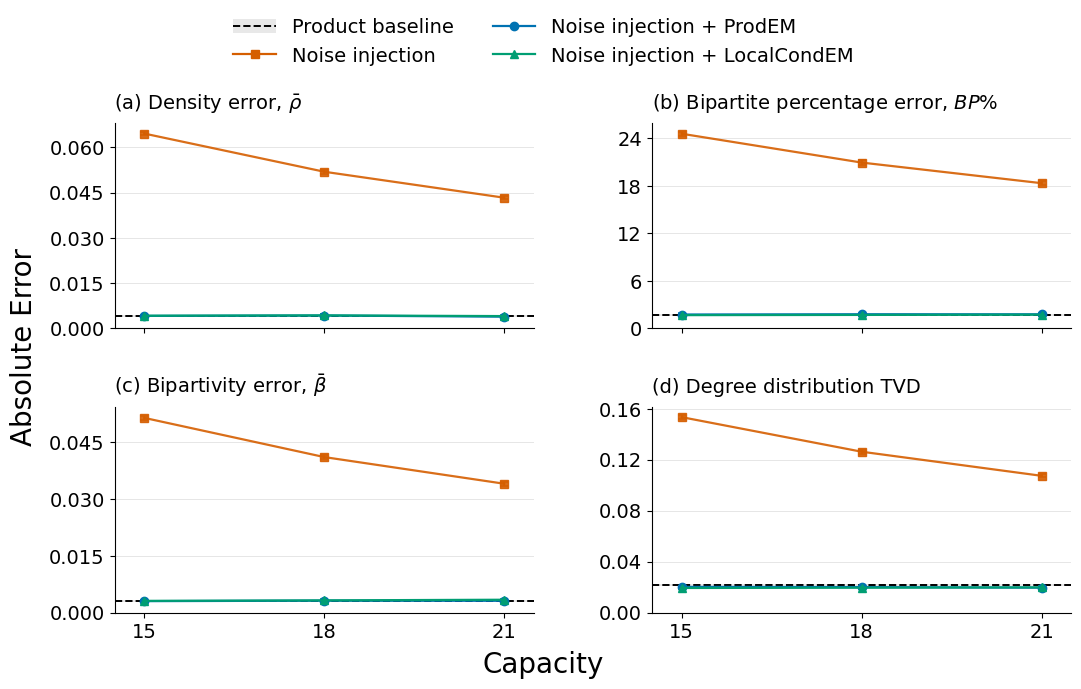

In [ ]:
METHOD_COLORS = {
    "DQC": "#D55E00",
    "DQC+ProdEM": "#0072B2",
    "DQC+LocalCondEM": "#009E73",
    "Product": "#000000",
}

METHOD_LABELS = {
    "DQC": "Noise injection",
    "DQC+ProdEM": "Noise injection + ProdEM",
    "DQC+LocalCondEM": "Noise injection + LocalCondEM",
}

MARKERS = {
    "DQC": "s",
    "DQC+ProdEM": "o",
    "DQC+LocalCondEM": "^",
}

METHOD_RESULTS = [
    ("DQC", dqc_results),
    ("DQC+ProdEM", prod_dqc_results),
    ("DQC+LocalCondEM", localcond_dqc_results),
]

METRICS = [
    ("density", r"(a) Density error, $\bar{\rho}$"),
    ("BP%", r"(b) Bipartite percentage error, $BP\%$"),
    ("beta", r"(c) Bipartivity error, $\bar{\beta}$"),
    ("tvd", "(d) Degree distribution TVD"),
]

method_results = {
    "Product": product_baseline_results,
    "DQC": dqc_results,
    "DQC+ProdEM": prod_dqc_results,
    "DQC+LocalCondEM": localcond_dqc_results,
}

metrics = ["density", "BP%", "beta", "tvd"]
capacities = [15, 18, 21]

quality_summary = {}
quality_comparisons = {}

for metric_idx, metric in enumerate(metrics):
    for capacity in capacities:
        summary, comparisons = bootstrap_sample_quality(
            method_results,
            metric=metric,
            capacity=capacity,
            n_bootstrap=5000,
            seed=42 + metric_idx,
        )
        quality_summary[metric, capacity] = summary
        quality_comparisons[metric, capacity] = comparisons

capacities = np.array([15, 18, 21])

fig, axes = plt.subplots(
    2, 2,
    figsize=(11, 7),
    sharex=True,
    sharey=False,
)

for ax, (metric, title) in zip(axes.flat, METRICS):

    # Preserve your existing baseline interval calculation.
    baseline = quality_summary[metric, 15]["Product"]
    baseline_mean = baseline["mean"]
    baseline_low, baseline_high = baseline["ci95"]

    ax.axhspan(
        baseline_low,
        baseline_high,
        color="0.5",
        alpha=0.18,
        linewidth=0,
        zorder=1,
    )
    ax.axhline(
        baseline_mean,
        color=METHOD_COLORS["Product"],
        linestyle="--",
        linewidth=1.4,
        zorder=2,
    )

    for method, results in METHOD_RESULTS:
        means = np.array([
            quality_summary[metric, cap][method]["mean"]
            for cap in capacities
        ])

        intervals = np.array([
            quality_summary[metric, cap][method]["ci95"]
            for cap in capacities
        ])

        yerr = np.vstack([
            means - intervals[:, 0],
            intervals[:, 1] - means,
        ])

        ax.errorbar(
            capacities,
            means,
            yerr=yerr,
            color=METHOD_COLORS[method],
            marker=MARKERS[method],
            markersize=6,
            linewidth=1.6,
            elinewidth=1.1,
            capsize=3,
            capthick=1.1,
            alpha=0.9 if method == "DQC" else 1.0,
            label=METHOD_LABELS[method],
            zorder=3,
        )

    ax.set_title(title, fontsize=14, loc="left", pad=10)
    ax.set_xlim(14.5, 21.5)
    ax.set_xticks(capacities)
    ax.tick_params(axis="both", labelsize=14)
    ax.yaxis.set_major_locator(MaxNLocator(nbins=5))

    # Absolute errors and TVD are nonnegative.
    ax.set_ylim(bottom=0)

    ax.set_axisbelow(True)
    ax.grid(axis="y", color="0.90", linewidth=0.7)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

# Shared legend: dashed baseline mean over its shaded interval.
baseline_handle = (
    Patch(facecolor="0.5", alpha=0.18, edgecolor="none"),
    Line2D([0], [0], color="black", linestyle="--", linewidth=1.4),
)

method_handles = [
    Line2D(
        [0], [0],
        color=METHOD_COLORS[method],
        marker=MARKERS[method],
        markersize=6,
        linewidth=1.6,
    )
    for method, _ in METHOD_RESULTS
]

fig.legend(
    [baseline_handle] + method_handles,
    ["Product baseline"] + [
        METHOD_LABELS[method] for method, _ in METHOD_RESULTS
    ],
    handler_map={tuple: HandlerTuple(ndivide=1)},
    loc="upper center",
    bbox_to_anchor=(0.5, 0.995),
    ncol=2,
    frameon=False,
    fontsize=14,
    columnspacing=2.0,
    handlelength=2.2,
)

fig.supxlabel("Capacity", fontsize=20, y=0.025)
fig.supylabel("Absolute Error", fontsize=20, x=0.015)

fig.subplots_adjust(
    left=0.11,
    right=0.98,
    bottom=0.12,
    top=0.82,
    wspace=0.28,
    hspace=0.38,
)

# Optional export:
fig.savefig("sample_quality_rnfixed.pdf", bbox_inches="tight")
# fig.savefig("sample_quality.png", dpi=300, bbox_inches="tight")

plt.show()